# De cinco frases al mapa

Cinco maneras de pedir gafas, más la palabra corta Gafas. Un embedding convierte cada frase en un vector, y este notebook mide qué tan cerca quedan y las dibuja.

Gafas es la consulta principal. En todos los gráficos va en azul, también en 3D, para ver dónde cae frente a las demás.

El catálogo de Lente indexa con `embed-v4.0` a 1536 dimensiones, porque ese modelo funde la foto con el texto. Aquí solo hay texto. Para reproducir el ejemplo de referencia usamos Cohere `embed-v5.0-fast`, que devuelve 2048 dimensiones. La clave sale de `backend/.env`.

No se toca Qdrant ni la colección `glasses`.


---

## Setup

Importa el backend y abre el cliente de Cohere. Corre el notebook desde `backend/` o desde `backend/notebooks/`.


In [20]:
import sys
from pathlib import Path

import cohere
import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
for candidate in (ROOT, ROOT.parent, ROOT / "backend", ROOT.parent / "backend"):
    if (candidate / "app").exists():
        BACKEND = candidate
        break
else:
    raise RuntimeError("Run this notebook from backend/ or from backend/notebooks/.")

sys.path.insert(0, str(BACKEND))

from app.config import Settings
from app.ssl import use_system_certificates

use_system_certificates()

settings = Settings()
co = cohere.Client(settings.cohere_api_key)
MODEL = "embed-v5.0-fast"
print("backend", BACKEND)
print("model", MODEL)


backend c:\Portfolio\embeddings_rag\episodio-1-intro-a-embeddings\backend
model embed-v5.0-fast


---

## 1. Las frases

Gafas es la consulta corta. Lentes es otra palabra para el mismo objeto. Las demás agregan color, quitan el color o cambian el uso.


In [21]:
PHRASES = [
    "Gafas",
    "Lentes",
    "Gafas de sol color gris",
    "Gafas de sol color negro",
    "Gafas de sol",
    "Gafas deportivas"
]
PHRASES


['Gafas',
 'Lentes',
 'Gafas de sol color gris',
 'Gafas de sol color negro',
 'Gafas de sol',
 'Gafas deportivas']

---

## 2. El embedding

`search_query` es el tipo de entrada que Cohere reserva para una consulta. `truncate="NONE"` falla si el texto no cabe, en vez de cortarlo en silencio. Estas frases caben enteras.

Cada respuesta es un vector de 2048 números. La celda siguiente imprime cada frase con el comienzo de su vector.


In [22]:
response = co.embed(
    model=MODEL,
    texts=PHRASES,
    input_type="search_query",
    truncate="NONE",
)
embeddings = np.asarray(response.embeddings, dtype=np.float64)
print(f"{embeddings.shape[0]} vectores de {embeddings.shape[1]} dimensiones")


6 vectores de 2048 dimensiones


In [23]:
for phrase, vector in zip(PHRASES, embeddings):
    preview = ", ".join(f"{value:.4f}" for value in vector[:8])
    print(f"{phrase}: [{preview}, ...]")


Gafas: [0.0073, 0.0350, -0.0547, 0.0161, -0.0097, -0.0056, -0.0477, -0.0184, ...]
Lentes: [0.0088, -0.0129, -0.0315, 0.0213, 0.0432, -0.0014, -0.0392, -0.0017, ...]
Gafas de sol color gris: [0.0196, 0.0008, -0.0446, 0.0247, 0.0060, -0.0016, -0.0031, -0.0146, ...]
Gafas de sol color negro: [0.0308, 0.0104, -0.0452, 0.0097, -0.0004, 0.0064, -0.0096, -0.0160, ...]
Gafas de sol: [0.0320, 0.0094, -0.0616, 0.0211, -0.0054, 0.0077, -0.0193, -0.0102, ...]
Gafas deportivas: [-0.0075, -0.0066, -0.0228, 0.0175, -0.0148, 0.0078, -0.0434, -0.0332, ...]


---

## 3. Similitud en el espacio completo

Cada vector se lleva a longitud 1. A partir de ahí el producto punto es la similitud coseno: 1 es la misma dirección y 0 es ortogonal.

La primera fila compara Gafas con el resto. Lo más cercano es Gafas deportivas (0.687) y Gafas de sol (0.633). Agregar el color las aleja (gris 0.472, negro 0.479). Lentes es la que más se separa (0.431). La diagonal es 1 porque cada frase se compara consigo misma.


In [24]:
def show_matrix(labels: list[str], scores: np.ndarray, decimals: int) -> None:
    """Print a square matrix with phrase labels on both axes."""
    width = max(len(label) for label in labels)
    print(" " * width + "".join(f"{label:>28}" for label in labels))
    for label, row in zip(labels, scores):
        print(f"{label:<{width}}" + "".join(f"{value:28.{decimals}f}" for value in row))


vectors = embeddings / np.linalg.norm(embeddings, axis=1, keepdims=True)
show_matrix(PHRASES, vectors @ vectors.T, 3)


                                               Gafas                      Lentes     Gafas de sol color gris    Gafas de sol color negro                Gafas de sol            Gafas deportivas
Gafas                                          1.000                       0.427                       0.469                       0.477                       0.632                       0.686
Lentes                                         0.427                       1.000                       0.388                       0.389                       0.514                       0.512
Gafas de sol color gris                        0.469                       0.388                       1.000                       0.745                       0.782                       0.622
Gafas de sol color negro                       0.477                       0.389                       0.745                       1.000                       0.818                       0.635
Gafas de sol                       

---

## 4. Verlas en 2D y en 3D

2048 ejes no se pueden dibujar. PCA se queda con las direcciones en las que estas frases más se separan: se centran los vectores ya normalizados, se descomponen con SVD y se toman las primeras componentes.

Gafas se dibuja en azul, más grande, en el plano y en el volumen. Así se lee la consulta principal contra las otras opciones.


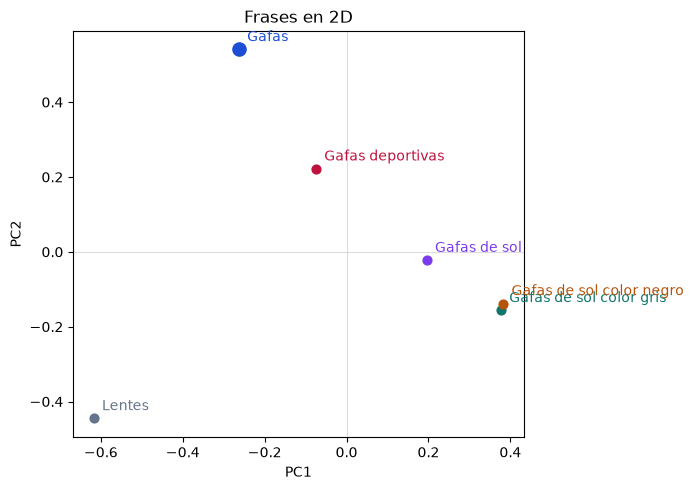

In [25]:
def project_phrases(matrix: np.ndarray, dims: int, *, unit: bool = False) -> np.ndarray:
    """Project L2-normalized rows onto the first `dims` principal components.

    `unit=True` L2-normalizes each projected point, so it lies on the circle or the sphere.
    """
    points = np.asarray(matrix, dtype=np.float64)
    points = points / np.linalg.norm(points, axis=1, keepdims=True)
    centered = points - points.mean(axis=0)
    _, _, vt = np.linalg.svd(centered, full_matrices=False)
    coords = centered @ vt[:dims].T
    if unit:
        coords = coords / np.linalg.norm(coords, axis=1, keepdims=True)
    return coords


PRIMARY_PHRASE = "Gafas"
PRIMARY_COLOR = "#1d4ed8"
OTHER_COLORS = ("#64748b", "#0f766e", "#b45309", "#7c3aed", "#be123c")


def phrase_color(label: str) -> str:
    """Return the primary blue for Gafas and a distinct color for every other phrase."""
    if label == PRIMARY_PHRASE:
        return PRIMARY_COLOR
    others = [name for name in PHRASES if name != PRIMARY_PHRASE]
    slot = others.index(label) if label in others else 0
    return OTHER_COLORS[slot % len(OTHER_COLORS)]


def phrase_size(label: str) -> float:
    """Draw the primary phrase larger than the variants."""
    return 90 if label == PRIMARY_PHRASE else 40


xy = project_phrases(embeddings, 2)
fig, ax = plt.subplots(figsize=(7, 5))
for label, (x, y) in zip(PHRASES, xy):
    ax.scatter(x, y, color=phrase_color(label), s=phrase_size(label), zorder=3)
    ax.annotate(label, (x, y), xytext=(6, 6), textcoords="offset points", color=phrase_color(label))
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_title("Frases en 2D")
ax.axhline(0, color="0.8", lw=0.5)
ax.axvline(0, color="0.8", lw=0.5)
fig.tight_layout()
plt.show()


[[-0.2629  0.5407 -0.2509]
 [-0.6174 -0.4453 -0.036 ]
 [ 0.3769 -0.1566 -0.1517]
 [ 0.3824 -0.1381  0.0051]
 [ 0.1956 -0.0225 -0.0021]
 [-0.0747  0.2217  0.4355]]


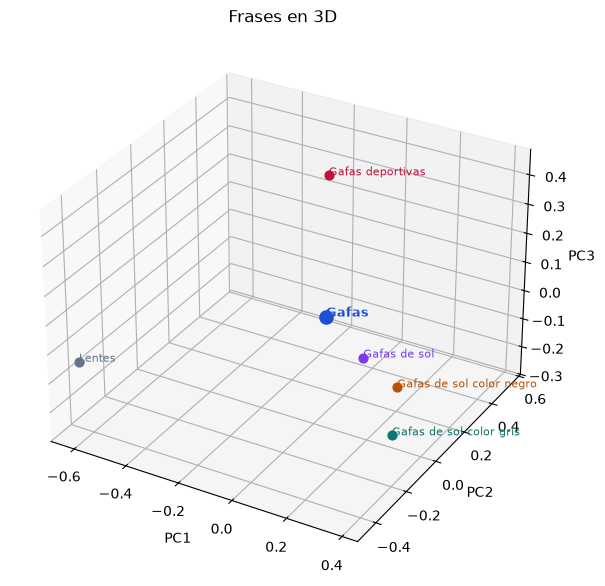

In [26]:
xyz = project_phrases(embeddings, 3)
print(np.round(xyz, 4))

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
for label, (x, y, z) in zip(PHRASES, xyz):
    ax.scatter(x, y, z, color=phrase_color(label), s=phrase_size(label), depthshade=False)
    ax.text(
        x,
        y,
        z,
        label,
        fontsize=9 if label == PRIMARY_PHRASE else 8,
        color=phrase_color(label),
        fontweight="bold" if label == PRIMARY_PHRASE else "normal",
    )
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")
ax.set_zlabel("PC3")
ax.set_title("Frases en 3D")
fig.tight_layout()
plt.show()


---

## 5. La misma proyección, sobre el círculo

Las coordenadas de PCA todavía tienen magnitud. Si cada punto se vuelve a normalizar, queda sobre el círculo (2D) o sobre la esfera (3D). Ahí se lee la dirección de la sombra, no lo lejos que quedó del origen.

Gafas sigue en azul en el círculo y en la esfera. Las gafas de sol caen juntas, las deportivas se apartan y lentes queda al otro extremo.


In [27]:
def labeled_coords(matrix: np.ndarray, labels: list[str], dims: int) -> list[tuple[str | float, ...]]:
    """Return `(phrase, c1, c2, ...)` on the unit circle or sphere, rounded to 4 decimals."""
    coords = np.round(project_phrases(matrix, dims, unit=True), 4)
    return [(label, *row.tolist()) for label, row in zip(labels, coords)]


print("2D  frase, x, y")
points_2d = labeled_coords(embeddings, PHRASES, 2)
for row in points_2d:
    print(row)

print()
print("3D  frase, x, y, z")
points_3d = labeled_coords(embeddings, PHRASES, 3)
for row in points_3d:
    print(row)


2D  frase, x, y
('Gafas', -0.4373, 0.8993)
('Lentes', -0.8111, -0.5849)
('Gafas de sol color gris', 0.9235, -0.3836)
('Gafas de sol color negro', 0.9406, -0.3396)
('Gafas de sol', 0.9934, -0.1143)
('Gafas deportivas', -0.3192, 0.9477)

3D  frase, x, y, z
('Gafas', -0.4035, 0.83, -0.3851)
('Lentes', -0.8102, -0.5843, -0.0472)
('Gafas de sol color gris', 0.8657, -0.3596, -0.3483)
('Gafas de sol color negro', 0.9405, -0.3395, 0.0125)
('Gafas de sol', 0.9934, -0.1143, -0.0107)
('Gafas deportivas', -0.1511, 0.4484, 0.881)


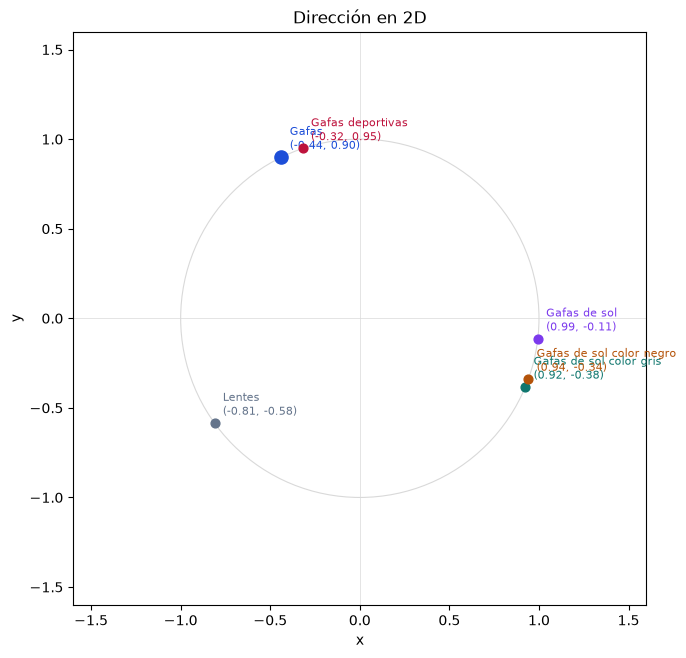

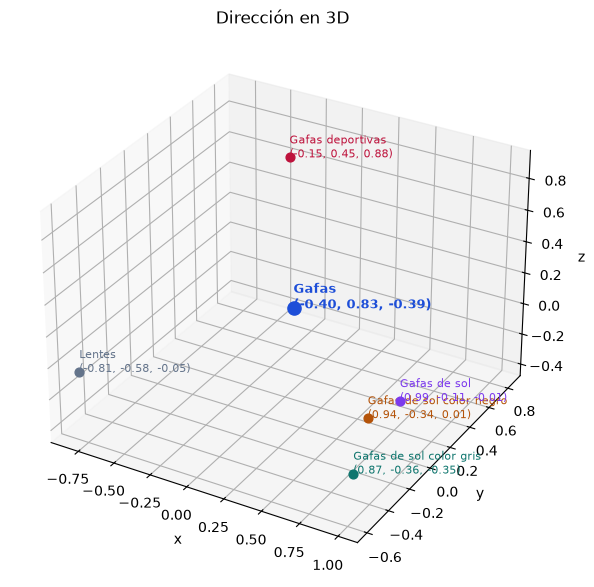

In [28]:
fig, ax = plt.subplots(figsize=(7, 7))
for label, x, y in points_2d:
    ax.scatter(x, y, color=phrase_color(label), s=phrase_size(label), zorder=3)
    ax.annotate(
        f"{label}\n({x:.2f}, {y:.2f})",
        (x, y),
        xytext=(6, 6),
        textcoords="offset points",
        fontsize=8,
        color=phrase_color(label),
    )
ax.add_patch(plt.Circle((0, 0), 1, fill=False, color="0.85", lw=0.8))
ax.set_aspect("equal")
ax.set_xlim(-1.6, 1.6)
ax.set_ylim(-1.6, 1.6)
ax.axhline(0, color="0.85", lw=0.5)
ax.axvline(0, color="0.85", lw=0.5)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Dirección en 2D")
fig.tight_layout()
plt.show()

fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d")
for label, x, y, z in points_3d:
    ax.scatter(x, y, z, color=phrase_color(label), s=phrase_size(label), depthshade=False)
    ax.text(
        x,
        y,
        z,
        f"{label}\n({x:.2f}, {y:.2f}, {z:.2f})",
        fontsize=9 if label == PRIMARY_PHRASE else 8,
        color=phrase_color(label),
        fontweight="bold" if label == PRIMARY_PHRASE else "normal",
    )
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.set_title("Dirección en 3D")
fig.tight_layout()
plt.show()


---

## 6. La sombra no es la distancia real

Esta similitud no es la de los 2048 ejes. Es la de los puntos ya proyectados, pasada al rango `[0, 1]` con `(coseno + 1) / 2`. 1 sigue siendo la misma dirección. 0 son direcciones opuestas.

En el plano, Gafas y Gafas deportivas parecen el mismo punto (0.996). En el espacio completo su coseno es 0.687. En 3D esa diferencia reaparece (0.549). El dibujo sirve para mirar. Una búsqueda compara el vector entero.


In [29]:
def pairwise_similarity(points: list[tuple[str | float, ...]]) -> np.ndarray:
    """Map cosine similarity of projected points into [0, 1].

    1 is the same direction. 0 is the opposite direction.
    """
    coords = np.asarray([row[1:] for row in points], dtype=np.float64)
    coords = coords / np.linalg.norm(coords, axis=1, keepdims=True)
    cosine = coords @ coords.T
    return np.round((cosine + 1) / 2, 4)


print("2D")
show_matrix(PHRASES, pairwise_similarity(points_2d), 4)
print()
print("3D")
show_matrix(PHRASES, pairwise_similarity(points_3d), 4)


2D
                                               Gafas                      Lentes     Gafas de sol color gris    Gafas de sol color negro                Gafas de sol            Gafas deportivas
Gafas                                         1.0000                      0.4143                      0.1256                      0.1416                      0.2314                      0.9959
Lentes                                        0.4143                      1.0000                      0.2377                      0.2179                      0.1305                      0.3523
Gafas de sol color gris                       0.1256                      0.2377                      1.0000                      0.9994                      0.9806                      0.1708
Gafas de sol color negro                      0.1416                      0.2179                      0.9994                      1.0000                      0.9866                      0.1890
Gafas de sol                    